# Final Project: Data Mining Analysis

# Load In The Data

First, load in the data generated from the EDA jupyter notebook.


In [1]:
import sys
from get_data.get_data import get_data

# Add paths so imports work with Jupyter Notebook relative imports. If this isn't done, any relative imports in any module imported will not work.
sys.path.append("./cluster_analysis")

data = get_data("../data/preprocessed/spotify_songs_preprocessed.csv")

# Cluster Analysis

Two clustering algorithms were employed: Kmeans and DBScan. Since our data set was mainly numerical, with values being between 0 and 1, Kmeans is appropriate. At the same time, our EDA work showed lots of outliers on various features, which would be a good reason to also try out DBScan, as a way to compare.


/Users/ewanbrinkman/.pyenv/versions/cmpt-353/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.3.4)
  from scipy.sparse import csr_matrix, issparse


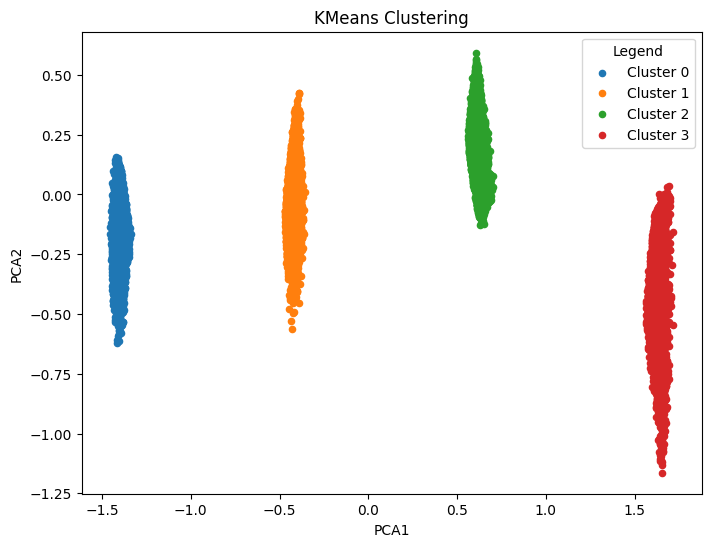

Silhouette Score: 0.6513580069173209


In [2]:
from cluster_analysis.kmeans_cluster import kmeans_cluster

kmeans_cluster(data['without_target'].copy())



DBSCAN Clusters:
Cluster
 0    12881
-1     3655
 2        9
 1        7
Name: count, dtype: int64


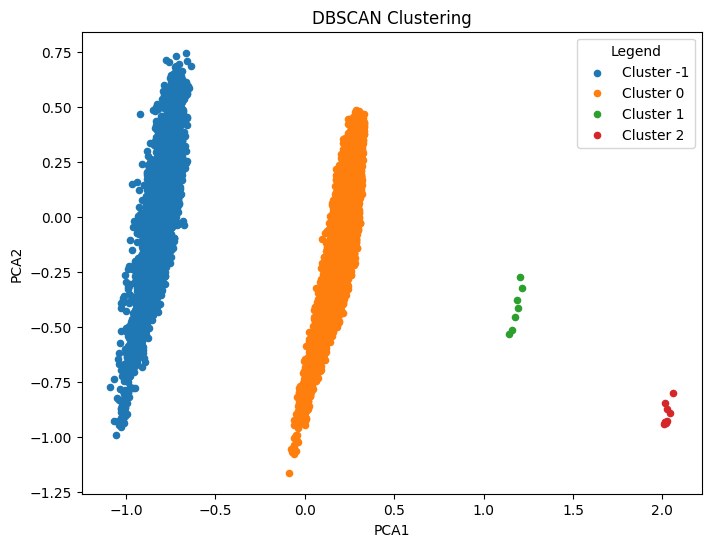

Silhouette Score: 0.5604750042265867


In [3]:
from cluster_analysis.dbscan_cluster import dbscans_cluster

dbscans_cluster(data['without_target'].copy())

# Outlier Detection

We did Local Outlier Factor and Isolation Forest on all 10 features at once for outlier detection. For each algorithm, a plot was created using PCA dimensionality reduction to 2 features (left plot), and another plot where each of the 10 features was plotted (right plot). Red dots are outliers and green dots are inliers. The scale is 0 to 1 for the right plot since all the 10 features are numerical and normalized in the 0 to 1 range. A key observation is that there appears to be quite a lot of noise from the outlier detection.

In [4]:
from outlier_detection.local_outlier_factor import calculate_outliers_local_outlier_factor
from outlier_detection.isolation_forest import calculate_outliers_isolation_forest
from outlier_detection.outlier_utils import print_outlier_amounts, print_outliers
from outlier_detection.plot_outliers import plot_outliers_pca_2, plot_outliers_each_dim

## Local Outlier Factor

In [5]:
predictions_lof = calculate_outliers_local_outlier_factor(data['without_target'].copy())
print_outlier_amounts(predictions_lof)


Inlier amount: 16478, Outlier amount: 74


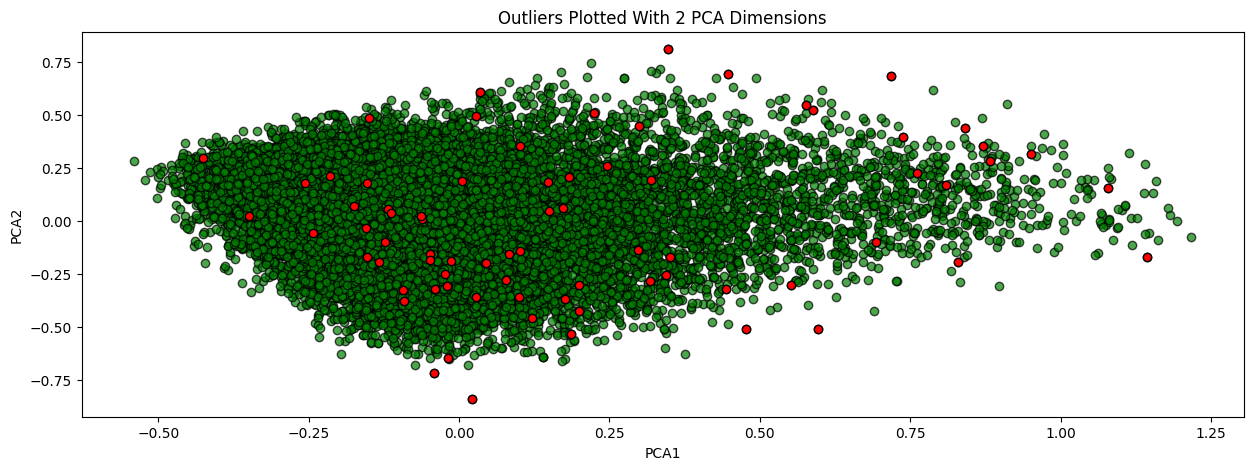

In [6]:
plot_outliers_pca_2(data['without_target'].copy(), predictions_lof)

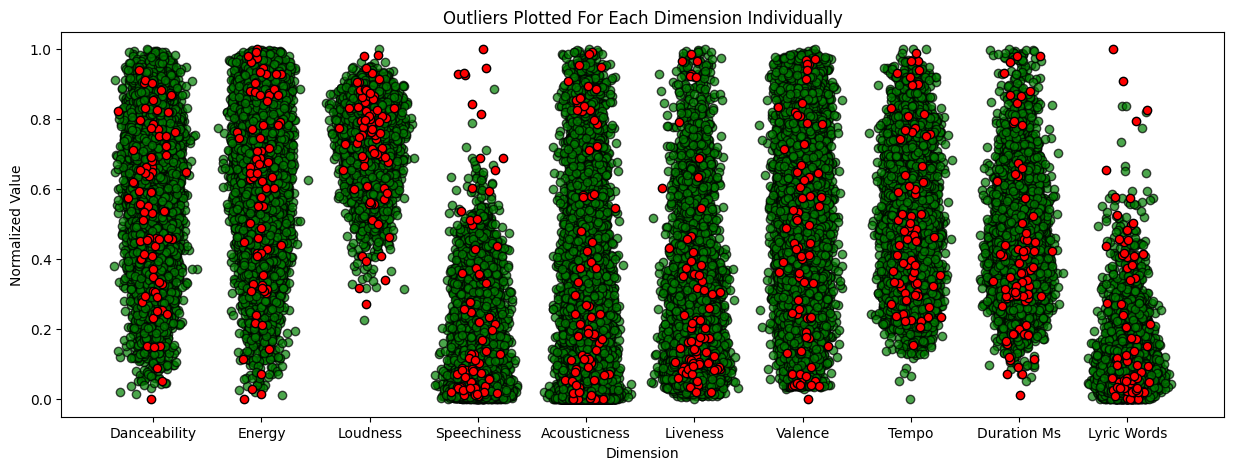

In [7]:
plot_outliers_each_dim(data['without_target'].copy(), predictions_lof)

## Isolation Forest


In [8]:
predictions_isolation_forest = calculate_outliers_isolation_forest(data['without_target'].copy())
print_outlier_amounts(predictions_isolation_forest)

Inlier amount: 16386, Outlier amount: 166


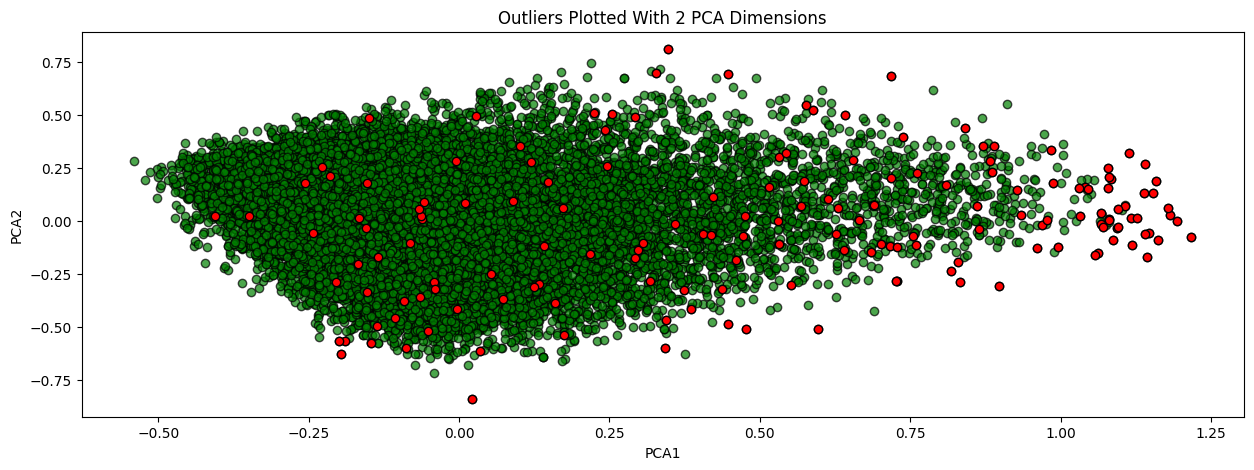

In [9]:
plot_outliers_pca_2(data['without_target'].copy(), predictions_isolation_forest)

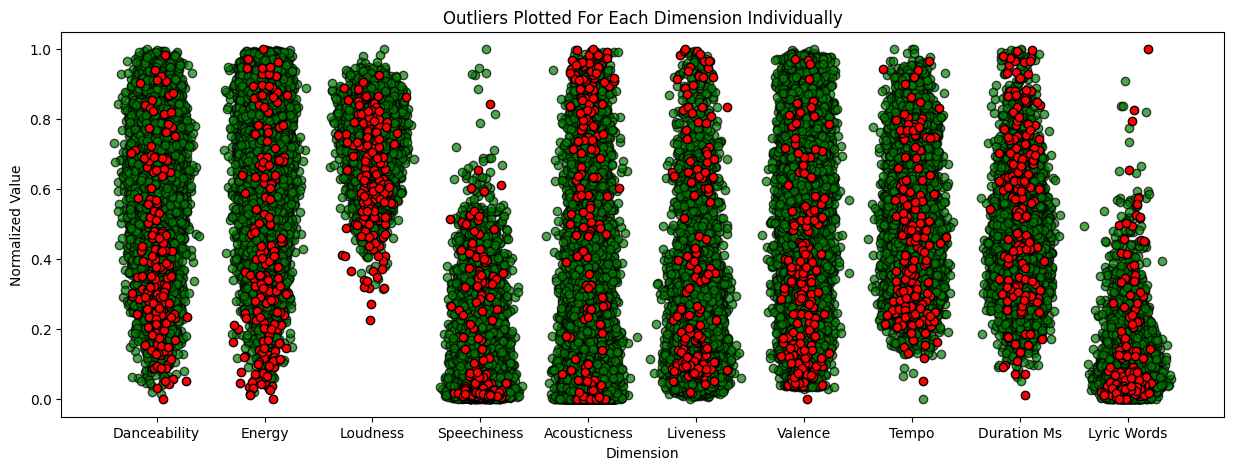

In [10]:
plot_outliers_each_dim(data['without_target'].copy(), predictions_isolation_forest)

### Further Outlier Comments

Another observation is for the plots on the right. All the outliers in the middle of the pack may not be an outlier for that specific feature, but may be an outlier because of another feature. For example, the red point at the very top of lyric words may be in the middle of danceability. Next, some of the points that are suspiciously far away from the clusters were manually verified. In the Jupyter Notebook, the Spotify song URL is pasted next to the suspicious outlier tracks, but all the songs flagged as outliers ended up being Ok and should stay in the dataset.


## Analysing The Suspicious Outliers

### Checking Loudness Outliers

2nH0gsXkSo8hsMv992jbTm - https://open.spotify.com/track/0MWdp2A6fbqplNSqqBToWK?si=5e7dc0567a354fb9

It is a normal track that just happens to be extra quiet.

3zksbXteOCeSusJ5Xltr3t - https://open.spotify.com/track/3zksbXteOCeSusJ5Xltr3t?si=e3d4a4584d8a40f7

It is a normal track that just happens to be extra quiet.

### Checking Speechiness Outliers

5ZbJR1AfdOsvsYNuCvgqKX - https://open.spotify.com/track/4y794Xfz4IEjKEdpXyMTOq?si=1cdcf292bd674218

It is a real track with a lot of talking since it is a rap song, so it should stay.

### Checking Duration Outliers

1rNNOKF4kiaNmdkpIKNsvd - https://open.spotify.com/track/0v2LUO8oTHnkjQ8MmKuXyk?si=9fc48826cd764e4a

It is very short 0:37 second song by Ariana Grande, but is a valid song and should be kept. It even has 142 million streams.

### Checking Lyric Word Amount Outliers

5yY9lUy8nbvjM1Uyo1Uqoc - https://open.spotify.com/track/5yY9lUy8nbvjM1Uyo1Uqoc?si=5332bc1444dd4f0e

A rap song that has layered vocals that causes the word count to be long. It is still a real song so should stay.



In [11]:
data_check_outliers = data['without_target'].copy()

# Check suspicious loudness outliers.
outliers_col = (data_check_outliers[predictions_isolation_forest == -1])['loudness']
check = outliers_col[outliers_col < 0.3]
print("Check loudness:")
print(check)

# Check suspicious speechiness outliers.
outliers_col = (data_check_outliers[predictions_lof == -1])['speechiness']
check = outliers_col[outliers_col > 0.95]
print("\nCheck speechiness:")
print(check)

# Check suspicious duration outliers.
outliers_col = (data_check_outliers[predictions_isolation_forest == -1])['duration_ms']
check = outliers_col[outliers_col < 0.05]
print("\nCheck duration ms:")
print(check)

# Check suspicious lyric words outliers.
outliers_col = (data_check_outliers[predictions_isolation_forest == -1])['lyric_words']
check = outliers_col[outliers_col > 0.9]
print("\nCheck lyric words:")
print(check)

Check loudness:
track_id
2nH0gsXkSo8hsMv992jbTm    0.225097
3zksbXteOCeSusJ5Xltr3t    0.271219
Name: loudness, dtype: float64

Check speechiness:
track_id
5ZbJR1AfdOsvsYNuCvgqKX    1.0
Name: speechiness, dtype: float64

Check duration ms:
track_id
1rNNOKF4kiaNmdkpIKNsvd    0.011827
Name: duration_ms, dtype: float64

Check lyric words:
track_id
5yY9lUy8nbvjM1Uyo1Uqoc    1.0
Name: lyric_words, dtype: float64


# Feature Selection

The feature selection is done using using Recursive Feature Elimination (RFE), implemented using RFECV from sklearn, with 3-fold cross-validation. Since classification later is using either using SVM or Random Forest models, the estimator used for RFE is will use both SVC and RandomForestClassifier.

The function calls below, prints how many of the features are optimal and which features are the optimal.

The code below takes a while to run (and so is commented out), but prior results was:

- Optimal number of features: 8 and Selected Features for Random Forest: 'loudness', 'speechiness', 'acousticness', 'liveness', 'valence',
  'tempo', 'duration_ms', 'lyric_words'

- Optimal number of features: 8, and selected Features for SVM: 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
  'tempo', 'duration_ms', 'lyric_words'

So, of the 10 features, 8/10 were found to be included in the optimal set of features. This means most of the features are kept, and just a couple (two) are discarded.


In [12]:
from feature_selection.feature_selectioin import get_features

# selected_data = get_features(data['without_target'], data['with_target'][ 'track_popularity_categorical'], model_name="rf")
# print("Selected Features for Random Forest: ")
# print(selected_data)

# selected_data = get_features(data['without_target'], data['with_target'][ 'track_popularity_categorical'], model_name="svm")
# print("Selected Features for SVM: ")
# print(selected_data)

optimal_features_rf = ['loudness', 'speechiness', 'acousticness', 'liveness', 'valence', 'tempo', 'duration_ms', 'lyric_words']
optimal_features_svm = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'tempo', 'duration_ms', 'lyric_words']

# Classification

For classification, SVM and Random Forest Classifier were used. The full dataset was split into training and testing sets using a 80% training and 20% testing split, and 5-fold cross-validation was employed on the training set. As in the feature selection section, metrics of Accuracy, Precision, Recall, F1-score, and AUC-ROC score were used throughout in evaluating the models. Additionally, Random Search was used for each classifier for hyperparameter tuning. We compare the performance of the model before and after tuning on the test set, using the prior mentioned metrics and also their classification reports.



## Classification (Without Optimal Features)


Random Forest Avg Cross-Validation Metrics: 
{'accuracy': 0.6103772557392119, 'precision': 0.6106780460548175, 'recall': 0.6103772557392119, 'f1_score': 0.6101984809648735, 'roc_auc_score': 0.6104551308310698}
SVM Avg Cross-Validation Metrics: 
{'accuracy': 0.6059210908978934, 'precision': 0.607681342678515, 'recall': 0.6059210908978934, 'f1_score': 0.6045703136664968, 'roc_auc_score': 0.6061313117656507}
Random Forest Test Set Metrics: 
{'accuracy': 0.5943823618242223, 'precision': 0.5945037207038781, 'recall': 0.5943823618242223, 'f1_score': 0.5943232300318363, 'roc_auc_score': 0.594431843972097}
SVM Test Set Metrics: 
{'accuracy': 0.6179401993355482, 'precision': 0.6197408764139093, 'recall': 0.6179401993355482, 'f1_score': 0.616725893051672, 'roc_auc_score': 0.6181631795224324}
Classification Report:
               precision    recall  f1-score   support

        high       0.60      0.58      0.59      1662
         low       0.59      0.61      0.60      1649

    accuracy       

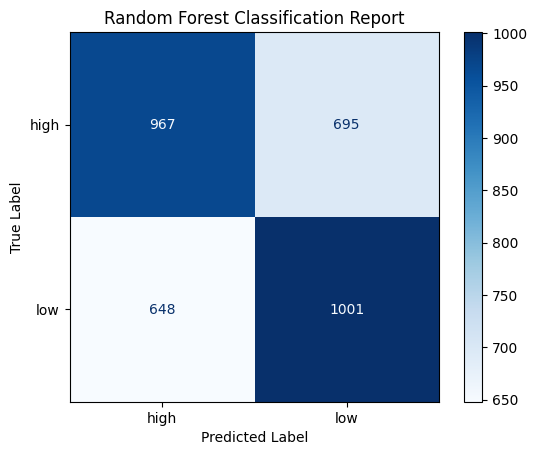

Classification Report:
               precision    recall  f1-score   support

        high       0.64      0.56      0.60      1662
         low       0.60      0.67      0.64      1649

    accuracy                           0.62      3311
   macro avg       0.62      0.62      0.62      3311
weighted avg       0.62      0.62      0.62      3311



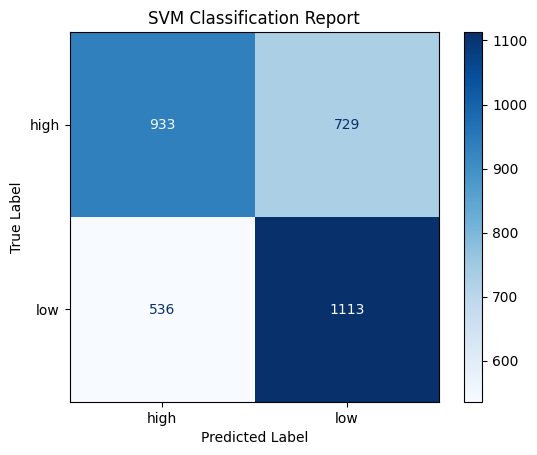

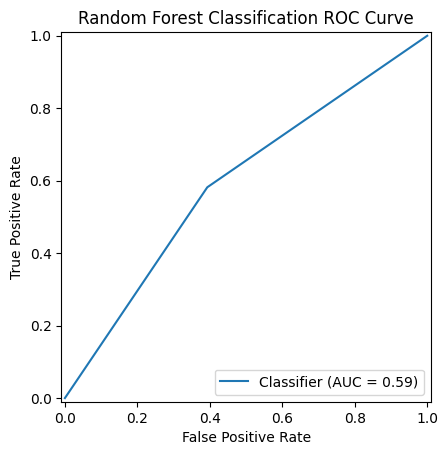

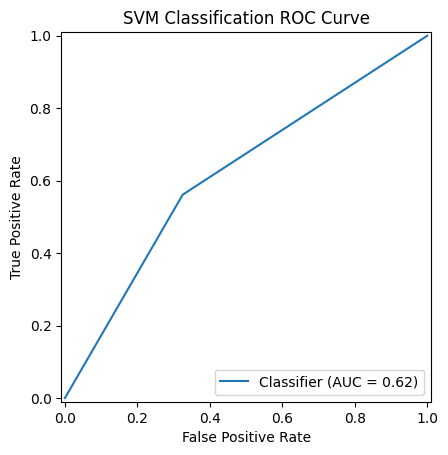

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from classification.get_classifcation_data import get_train_and_test_data
from classification.evaluate_models import cv_with_metrics, get_model_evaluation_metrics, visualize_model_with_classification_report, visualize_model_with_roc_score


# models
random_forest_model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
    )
svm_model = SVC(kernel="linear", random_state=42)

# get train and test data, only selecting optimal features
target = data['with_target']['track_popularity_categorical']
X = data['without_target']
X_train, X_test, y_train, y_test = get_train_and_test_data(X, target, optimal_features=None)

#cross-validation with metrics
rf_avg_metrics = cv_with_metrics(random_forest_model, X_train, y_train, cv=5)
print("Random Forest Avg Cross-Validation Metrics: ")
print(rf_avg_metrics)

svm_avg_metrics = cv_with_metrics(svm_model, X_train, y_train, cv=5)
print("SVM Avg Cross-Validation Metrics: ")
print(svm_avg_metrics)

#train and evaluate on test set
random_forest_model.fit(X_train, y_train)
y_pred_rf = random_forest_model.predict(X_test)
rf_test_metrics = get_model_evaluation_metrics(y_test, y_pred_rf)
print("Random Forest Test Set Metrics: ")
print(rf_test_metrics)

svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)
svm_test_metrics = get_model_evaluation_metrics(y_test, y_pred_svm)
print("SVM Test Set Metrics: ")
print(svm_test_metrics)

# visualize classification report and roc curve
visualize_model_with_classification_report(y_test, y_pred_rf, plot_title="Random Forest Classification Report")
visualize_model_with_classification_report(y_test, y_pred_svm, plot_title="SVM Classification Report")

visualize_model_with_roc_score(y_test, y_pred_rf, plot_title="Random Forest Classification ROC Curve")
visualize_model_with_roc_score(y_test, y_pred_svm, plot_title="SVM Classification ROC Curve")


##  Classification (With Optimal Features)

Notice here that the model does not change that much with the optimal features.


Random Forest Avg Cross-Validation Metrics: 
{'accuracy': 0.5997283646910023, 'precision': 0.6000436366964184, 'recall': 0.5997283646910023, 'f1_score': 0.599509397752028, 'roc_auc_score': 0.5998056024850771}
SVM Avg Cross-Validation Metrics: 
{'accuracy': 0.6064498773407054, 'precision': 0.6087375468395988, 'recall': 0.6064498773407054, 'f1_score': 0.6046654321869049, 'roc_auc_score': 0.6066956704852144}
Random Forest Test Set Metrics: 
{'accuracy': 0.5889459377831471, 'precision': 0.5891680348056596, 'recall': 0.588945937783147, 'f1_score': 0.5888010132356932, 'roc_auc_score': 0.5890214249382808}
SVM Test Set Metrics: 
{'accuracy': 0.6191482935668983, 'precision': 0.6213875981106599, 'recall': 0.6191482935668983, 'f1_score': 0.6176338717295605, 'roc_auc_score': 0.619397381193722}
Classification Report:
               precision    recall  f1-score   support

        high       0.59      0.57      0.58      1662
         low       0.58      0.61      0.60      1649

    accuracy       

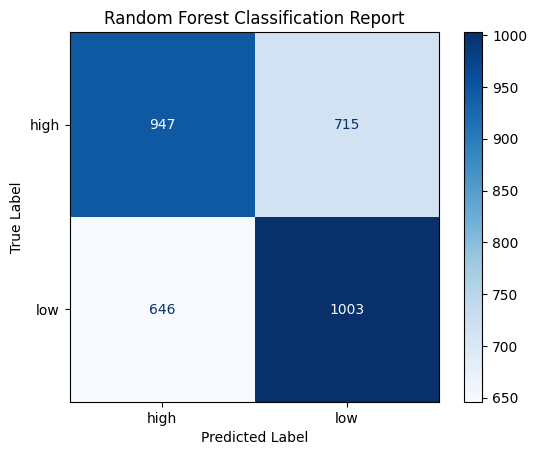

Classification Report:
               precision    recall  f1-score   support

        high       0.64      0.56      0.59      1662
         low       0.60      0.68      0.64      1649

    accuracy                           0.62      3311
   macro avg       0.62      0.62      0.62      3311
weighted avg       0.62      0.62      0.62      3311



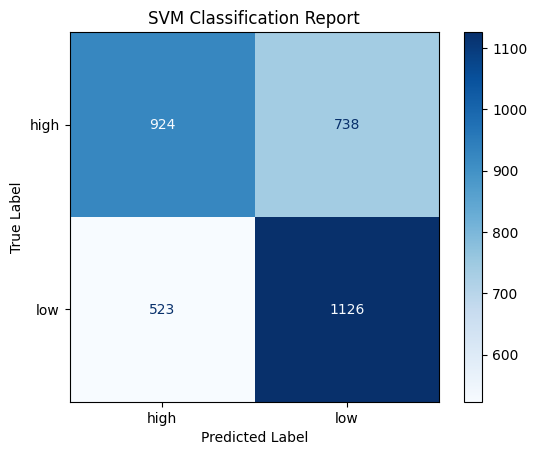

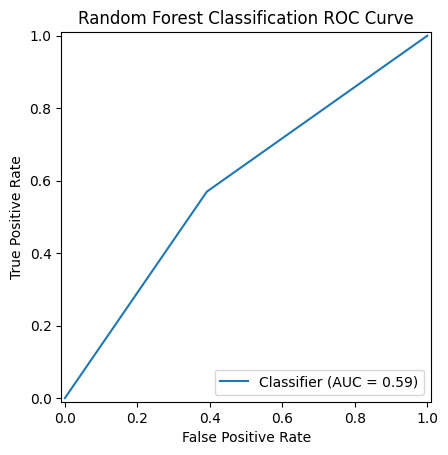

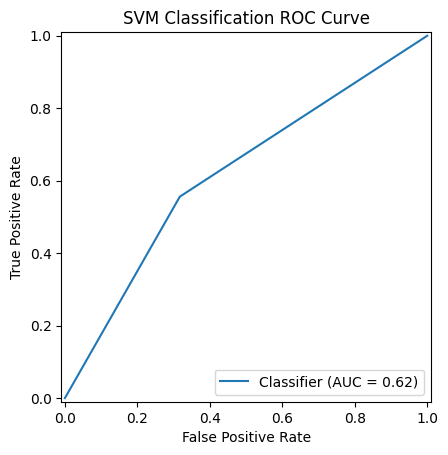

In [14]:
# models
random_forest_model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
    )
svm_model = SVC(kernel="linear", random_state=42)

# get train and test data, only selecting optimal features
target = data['with_target']['track_popularity_categorical']
X = data['without_target']
X_train_rf, X_test_rf, y_train_rf, y_test_rf = get_train_and_test_data(X, target, optimal_features=optimal_features_rf)
X_train_svm, X_test_svm, y_train_svm, y_test_svm = get_train_and_test_data(X, target, optimal_features=optimal_features_svm)

#cross-validation with metrics
rf_avg_metrics = cv_with_metrics(random_forest_model, X_train_rf, y_train_rf, cv=5)
print("Random Forest Avg Cross-Validation Metrics: ")
print(rf_avg_metrics)

svm_avg_metrics = cv_with_metrics(svm_model, X_train_svm, y_train_svm, cv=5)
print("SVM Avg Cross-Validation Metrics: ")
print(svm_avg_metrics)

#train and evaluate on test set
random_forest_model.fit(X_train_rf, y_train_rf)
y_pred_rf = random_forest_model.predict(X_test_rf)
rf_test_metrics = get_model_evaluation_metrics(y_test_rf, y_pred_rf)
print("Random Forest Test Set Metrics: ")
print(rf_test_metrics)

svm_model.fit(X_train_svm, y_train_svm)
y_pred_svm = svm_model.predict(X_test_svm)
svm_test_metrics = get_model_evaluation_metrics(y_test_svm, y_pred_svm)
print("SVM Test Set Metrics: ")
print(svm_test_metrics)

# visualize classification report and roc curve
visualize_model_with_classification_report(y_test_rf, y_pred_rf, plot_title="Random Forest Classification Report")
visualize_model_with_classification_report(y_test_svm, y_pred_svm, plot_title="SVM Classification Report")

visualize_model_with_roc_score(y_test, y_pred_rf, plot_title="Random Forest Classification ROC Curve")
visualize_model_with_roc_score(y_test, y_pred_svm, plot_title="SVM Classification ROC Curve")

# Hyperparameter Tuning

Here 3 folds with 15 candidates, for 45 total fits are done for each of the forest and SVM models.


In [15]:
from classification.hyperparameter_tuning import tune_random_forest_model


best_random_forest_estimator = tune_random_forest_model(X_train, y_train)
print("Best Random Forest Estimator: ")
print(best_random_forest_estimator)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


/Users/ewanbrinkman/.pyenv/versions/cmpt-353/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.3.4)
  from scipy.sparse import csr_matrix, issparse
/Users/ewanbrinkman/.pyenv/versions/cmpt-353/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.3.4)
  from scipy.sparse import csr_matrix, issparse
/Users/ewanbrinkman/.pyenv/versions/cmpt-353/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.3.4)
  from scipy.sparse import csr_matrix, issparse
/Users/ewanbrinkman/.pyenv/versions/cmpt-353/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for thi

Best RF params: {'bootstrap': True, 'max_depth': 25, 'max_features': None, 'min_samples_leaf': 8, 'min_samples_split': 5, 'n_estimators': 459}
Best RF CV score: 0.6130197837511906
Best Random Forest Estimator: 
RandomForestClassifier(max_depth=25, max_features=None, min_samples_leaf=8,
                       min_samples_split=5, n_estimators=459, n_jobs=-1,
                       random_state=42)


Past output was:

Best RF params: {'bootstrap': True, 'max_depth': 25, 'max_features': None, 'min_samples_leaf': 8, 'min_samples_split': 5, 'n_estimators': 459}
Best RF CV score: 0.6130197837511906
Best Random Forest Estimator:
RandomForestClassifier(max_depth=25, max_features=None, min_samples_leaf=8,
                       min_samples_split=5, n_estimators=459, n_jobs=-1,
                       random_state=42)

In [16]:
from classification.hyperparameter_tuning import tune_svm_model


best_svm_estimator = tune_svm_model(X_train, y_train)
print("Best SVM Estimator: ")
print(best_svm_estimator)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best SVM params: {'C': np.float64(5.651157902710025), 'kernel': 'rbf'}
Best SVM CV score: 0.6134726137125647
Best SVM Estimator: 
SVC(C=np.float64(5.651157902710025), random_state=42)


Past output was:

Best SVM params: {'C': np.float64(5.651157902710025), 'kernel': 'rbf'}
Best SVM CV score: 0.6134726137125647
Best SVM Estimator:
SVC(C=np.float64(5.651157902710025), random_state=42)

## Classification (With Hyperparameter Tuning)

The professor said to just do the hyperparameter tuned classification using the found optimal features.

Comparing between hyperparameter tuning and and no tuning, there was a very slight improvement overall. For the 5-fold cross validation values, hyperparameter tuning increased most of the metrics by around 0.01 to 0.03. Similar trends held for the metrics of the test set as well, and this is shown in detail below with classification report and the ROC curve comparison between, before and after hyperparameter tuning. We do notice that SVM did not improve after hyperparameter tuning in terms of classifying the “high” values, but all other classifications improved after tuning in both the Classification report and ROC Curve.


Random Forest Avg Cross-Validation Metrics: 
{'accuracy': 0.6099242260945532, 'precision': 0.6103003688024158, 'recall': 0.6099242260945532, 'f1_score': 0.6096915804000383, 'roc_auc_score': 0.6100071399081269}
SVM Avg Cross-Validation Metrics: 
{'accuracy': 0.6181564553231624, 'precision': 0.6223188970898517, 'recall': 0.6181564553231624, 'f1_score': 0.6151850250941642, 'roc_auc_score': 0.6184772738552408}
Random Forest Test Set Metrics: 
{'accuracy': 0.6013289036544851, 'precision': 0.6014595544991055, 'recall': 0.6013289036544851, 'f1_score': 0.6012678018266086, 'roc_auc_score': 0.6013796787463357}
SVM Test Set Metrics: 
{'accuracy': 0.6188462700090607, 'precision': 0.6230414976903611, 'recall': 0.6188462700090607, 'f1_score': 0.6159123762916326, 'roc_auc_score': 0.6191914072562666}
Classification Report:
               precision    recall  f1-score   support

        high       0.61      0.59      0.60      1662
         low       0.60      0.61      0.61      1649

    accuracy    

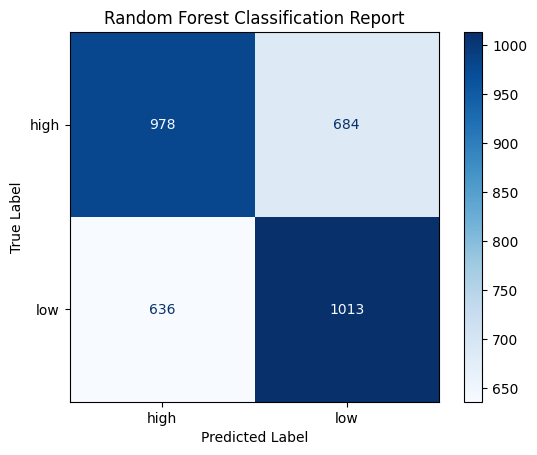

Classification Report:
               precision    recall  f1-score   support

        high       0.65      0.53      0.58      1662
         low       0.60      0.71      0.65      1649

    accuracy                           0.62      3311
   macro avg       0.62      0.62      0.62      3311
weighted avg       0.62      0.62      0.62      3311



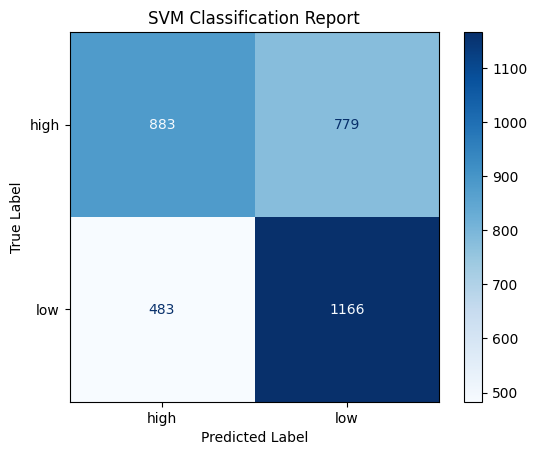

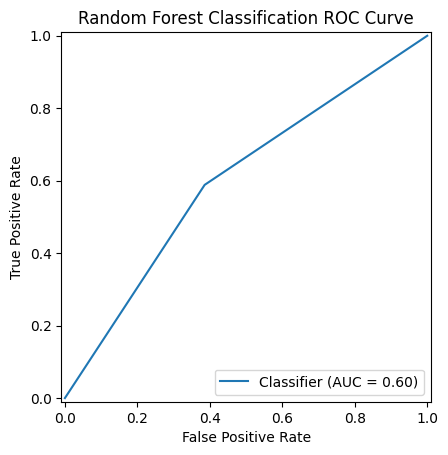

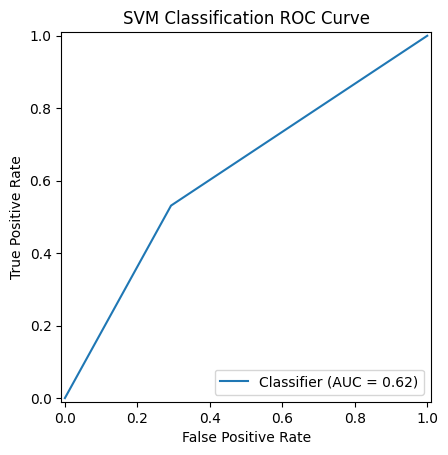

In [17]:
# models
random_forest_model = best_random_forest_estimator
svm_model = best_svm_estimator

# get train and test data, only selecting optimal features
target = data['with_target']['track_popularity_categorical']
X = data['without_target']
X_train_rf, X_test_rf, y_train_rf, y_test_rf = get_train_and_test_data(X, target, optimal_features=optimal_features_rf)
X_train_svm, X_test_svm, y_train_svm, y_test_svm = get_train_and_test_data(X, target, optimal_features=optimal_features_svm)

#cross-validation with metrics
rf_avg_metrics = cv_with_metrics(random_forest_model, X_train_rf, y_train_rf, cv=5)
print("Random Forest Avg Cross-Validation Metrics: ")
print(rf_avg_metrics)

svm_avg_metrics = cv_with_metrics(svm_model, X_train_svm, y_train_svm, cv=5)
print("SVM Avg Cross-Validation Metrics: ")
print(svm_avg_metrics)

#train and evaluate on test set
random_forest_model.fit(X_train_rf, y_train_rf)
y_pred_rf = random_forest_model.predict(X_test_rf)
rf_test_metrics = get_model_evaluation_metrics(y_test_rf, y_pred_rf)
print("Random Forest Test Set Metrics: ")
print(rf_test_metrics)

svm_model.fit(X_train_svm, y_train_svm)
y_pred_svm = svm_model.predict(X_test_svm)
svm_test_metrics = get_model_evaluation_metrics(y_test_svm, y_pred_svm)
print("SVM Test Set Metrics: ")
print(svm_test_metrics)

# visualize classification report and roc curve
visualize_model_with_classification_report(y_test_rf, y_pred_rf, plot_title="Random Forest Classification Report")
visualize_model_with_classification_report(y_test_svm, y_pred_svm, plot_title="SVM Classification Report")

visualize_model_with_roc_score(y_test, y_pred_rf, plot_title="Random Forest Classification ROC Curve")
visualize_model_with_roc_score(y_test, y_pred_svm, plot_title="SVM Classification ROC Curve")